## Import Library

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

## Load Dataset

In [50]:
df = pd.read_csv('../sales_data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   str    
 2   Sales_Rep             1000 non-null   str    
 3   Region                1000 non-null   str    
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   str    
 7   Unit_Cost             1000 non-null   float64
 8   Unit_Price            1000 non-null   float64
 9   Customer_Type         1000 non-null   str    
 10  Discount              1000 non-null   float64
 11  Payment_Method        1000 non-null   str    
 12  Sales_Channel         1000 non-null   str    
 13  Region_and_Sales_Rep  1000 non-null   str    
dtypes: float64(4), int64(2), str(8)
memory usage: 109.5 KB


In [51]:
df.head(10)

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie
5,1021,2023-02-11,Charlie,West,3761.15,32,Food,900.79,1106.51,New,0.21,Cash,Online,West-Charlie
6,1083,2023-04-11,Bob,West,618.31,29,Furniture,2408.81,2624.09,Returning,0.14,Cash,Online,West-Bob
7,1087,2023-01-06,Eve,South,7698.92,46,Furniture,3702.51,3964.65,New,0.12,Bank Transfer,Online,South-Eve
8,1075,2023-06-29,David,South,4223.39,30,Furniture,738.06,1095.45,New,0.05,Bank Transfer,Online,South-David
9,1075,2023-10-09,Charlie,West,8239.58,18,Clothing,2228.35,2682.34,New,0.13,Bank Transfer,Online,West-Charlie


In [52]:
df.tail(10)

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
990,1017,2023-01-20,Bob,East,496.59,29,Clothing,3410.49,3481.72,New,0.24,Bank Transfer,Retail,East-Bob
991,1013,2023-06-01,Charlie,East,2985.46,16,Furniture,1222.15,1284.36,Returning,0.03,Credit Card,Retail,East-Charlie
992,1084,2023-02-19,David,West,2154.66,35,Food,465.61,812.91,New,0.16,Bank Transfer,Online,West-David
993,1025,2023-06-26,David,North,2457.65,47,Furniture,3861.61,3998.91,New,0.25,Credit Card,Online,North-David
994,1068,2023-04-06,Alice,South,9093.50,31,Clothing,3169.37,3304.15,Returning,0.25,Credit Card,Retail,South-Alice
995,1010,2023-04-15,Charlie,North,4733.88,4,Food,4943.03,5442.15,Returning,0.29,Cash,Online,North-Charlie
996,1067,2023-09-07,Bob,North,4716.36,37,Clothing,1754.32,1856.40,New,0.21,Bank Transfer,Retail,North-Bob
997,1018,2023-04-27,David,South,7629.70,17,Clothing,355.72,438.27,Returning,0.06,Bank Transfer,Online,South-David
998,1100,2023-12-20,David,West,1629.47,39,Electronics,3685.03,3743.39,New,0.01,Bank Transfer,Online,West-David
999,1086,2023-08-16,Alice,East,4923.93,48,Food,2632.58,2926.68,Returning,0.14,Cash,Online,East-Alice


In [53]:
df.isnull().sum()

Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64

## Bar Chart

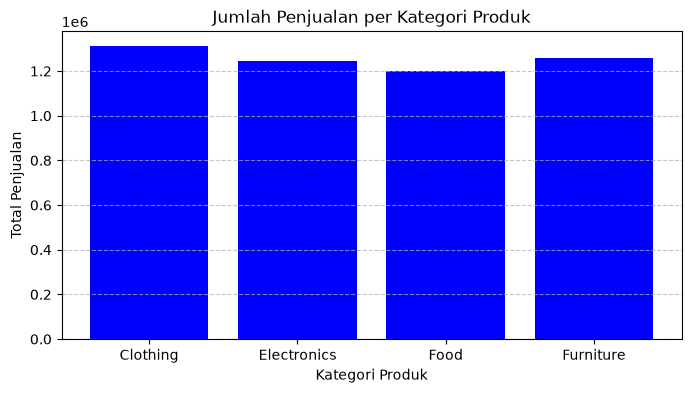

In [54]:
# Total Pendapatan per Kategori
# Langkah: Groupby Kategori -> Sum Pendapatan -> Bar Chart

cat_revenue = df.groupby('Product_Category')['Sales_Amount'].sum().reset_index()

plt.figure(figsize=(8, 4))
plt.bar(cat_revenue['Product_Category'], cat_revenue['Sales_Amount'], color='blue')
plt.title('Jumlah Penjualan per Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Penjualan')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Line Chart

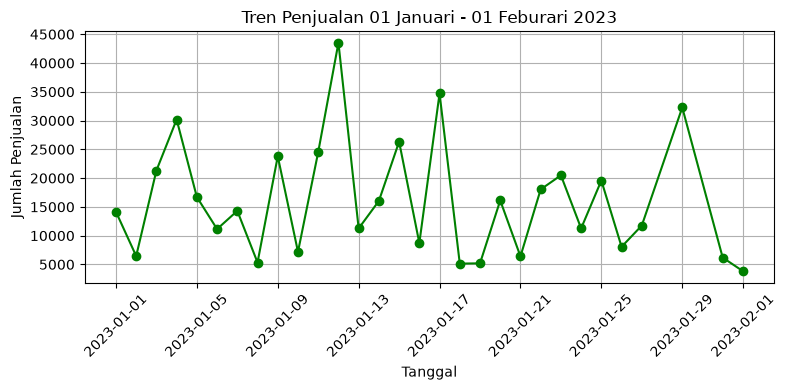

In [55]:
# Tren Penjualan Harian
# Langkah: Groupby Tanggal -> Sum Pendapatan -> Line Chart

df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])

start_date = '2023-01-01'
end_date = '2023-02-01'

filtered_df = df[(df['Sale_Date'] >= start_date) & (df['Sale_Date'] <= end_date)]
filtered_df = filtered_df.groupby('Sale_Date')['Sales_Amount'].sum().reset_index()

plt.figure(figsize=(8, 4))
plt.plot(filtered_df['Sale_Date'], filtered_df['Sales_Amount'], marker='o', color='green')
plt.title('Tren Penjualan 01 Januari - 01 Feburari 2023')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Scatter Plot

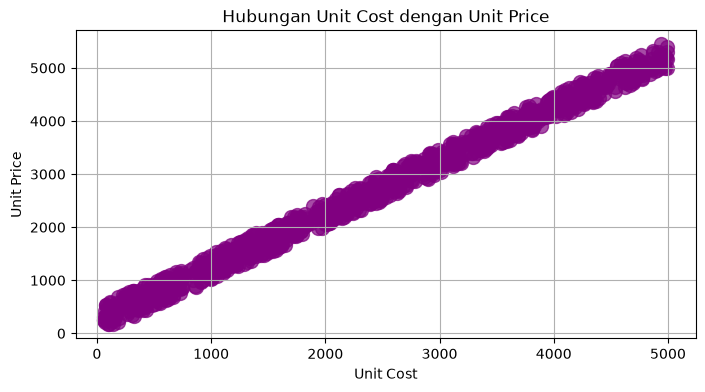

In [56]:
# Hubungan Unit Cost vs Unit Price
plt.figure(figsize=(8, 4))
plt.scatter(df['Unit_Cost'], df['Unit_Price'], color='purple', alpha=0.7, s=100)
plt.title('Hubungan Unit Cost dengan Unit Price')
plt.xlabel('Unit Cost')
plt.ylabel('Unit Price')
plt.grid(True)
plt.show()

## Histogram

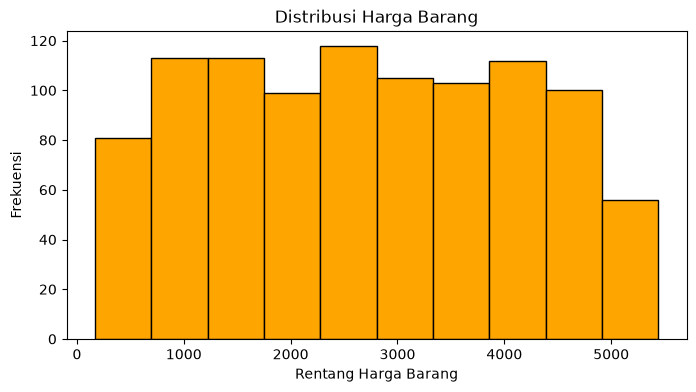

In [57]:
# Distribusi Harga Barang
plt.figure(figsize=(8, 4))
plt.hist(df['Unit_Price'], bins=10, color='orange', edgecolor='black')
plt.title('Distribusi Harga Barang')
plt.xlabel('Rentang Harga Barang')
plt.ylabel('Frekuensi')
plt.show()